# Extended EDA – Global Health Network

The **initial EDA** (`initial_eda.ipynb`) checked the structure and quality of the raw merged data and produced the cleaning rules implemented in `clean_dataset.py`. This notebook is the **extended EDA** on the cleaned data: one row per country for **2019**, with **71 indicators** and **139 causes of death** for **182 countries**.

**Goal of this notebook.** Understand the relationships in the data before building the network:

1. **Sample** – which countries are in the data? (Section 1)
2. **Health systems and outcomes** – how do key indicators differ between rich and poor countries? (Section 2)
3. **Causes of death** – what do people die of, and how does this change with wealth? (Section 3)
4. **Correlations between indicators** – which indicators move together, which are redundant? (Section 4)
5. **Causes of death vs. health system** – which causes are related to health-system coverage *beyond* national wealth? (Section 5)
6. **Correlations between causes** – which causes occur together, and how much of this is only wealth? This is a first look at the disease communities of the network. (Section 6)
7. **Dimensionality and outliers** – how many dimensions describe the countries, and which countries are extreme? (Sections 7 and 8)

Section 9 summarises the findings and the consequences for the network.

**Method notes**
- Correlations are **Spearman rank correlations** throughout. They compare rankings rather than raw values, so they are robust to the strong skewness found in the initial EDA and to many zeros (e.g. malaria).
- Plots use the original scale (`clean_2019.csv`); the PCA uses the log-transformed file (`clean_2019_log.csv`).
- Countries are coloured by **World Bank income group** (light blue = low income → dark blue = high income) in all charts.

## 0 Setup
Libraries, plot style and colours. The colours are fixed once here so that every chart uses the same colour for the same thing:
- **income groups**: one blue ramp from light (low income) to dark (high income), because income groups are ordered,
- **categories** (e.g. the three broad cause groups): blue, orange, green,
- **correlations**: a diverging scale from blue (−1) over gray (0) to red (+1).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- Plot style: light grid, no top/right frame, small font --------------------------------
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.axisbelow": True,
})

# --- Colours (fixed, so every chart uses the same colour for the same thing) ---------------
INCOME_ORDER = ["Low income", "Lower middle income", "Upper middle income", "High income"]
INCOME_COLORS = dict(zip(INCOME_ORDER, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))  # light -> dark blue = poor -> rich
CATEGORY_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]                                       # blue, orange, green
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])  # -1 blue, 0 gray, +1 red

### 0.1 Loading the data
- `clean` – cleaned 2019 data, original scale (for plots and tables)
- `clean_log` – the same with `log(1 + x)` applied to skewed columns (for PCA)
- `dictionary` – group of every column (`system_input`, `risk_factor`, …)
- `full` – the full merged panel, only needed for the broad cause groups (communicable / noncommunicable / injuries), which are not in the cleaned file because only the detailed causes are kept there.

`label()` turns column names into readable labels for the charts.

In [2]:
# Cleaned cross-section 2019 (one row per country), on the original scale and log-transformed
clean = pd.read_csv("../data/processed/clean_2019.csv")
clean_log = pd.read_csv("../data/processed/clean_2019_log.csv")

# Data dictionary (group of every column) and the full panel (for the cause groups, which are not in the clean file)
dictionary = pd.read_csv("../data/preprocessed/dictionary.csv")
full = pd.read_csv("../data/preprocessed/global_health_dataset.csv")

ID_COLS = ["iso3", "country", "region", "income_group"]
cause_cols = [c for c in clean.columns if c.startswith("death_asdr_")]
indicator_cols = [c for c in clean.columns if c not in ID_COLS and c not in cause_cols]

# Group of every indicator (battle deaths were renamed in the cleaning script)
group_of = dictionary.set_index("column")["group"].to_dict()
group_of["battle_deaths_per100k"] = "context"


def label(col):
    """Readable label for a column name.

    Parameters
    col: str, column name, e.g. "death_asdr_ischaemic_heart_disease"

    Returns
    str, e.g. "ischaemic heart disease"
    """
    return col.replace("death_asdr_", "").replace("_", " ")


print(clean.shape, "->", len(indicator_cols), "indicators and", len(cause_cols), "causes of death for",
      len(clean), "countries")
print(pd.Series([group_of[c] for c in indicator_cols]).value_counts().to_string())

(182, 214) -> 71 indicators and 139 causes of death for 182 countries
treatment_availability    16
system_input              13
risk_factor               12
system_output             10
outcome                   10
context                   10


**Result.** 182 countries with 71 indicators and 139 causes of death. The indicators cover six groups; the largest is **treatment availability** (16 yes/no indicators from the WHO NCD country capacity survey), followed by **system inputs** (13) and **risk factors** (12).

## 1 Sample: countries per income group and region
Before interpreting any relationship it is important to know how the sample is composed. If one group of countries dominated, correlations would mainly describe that group.

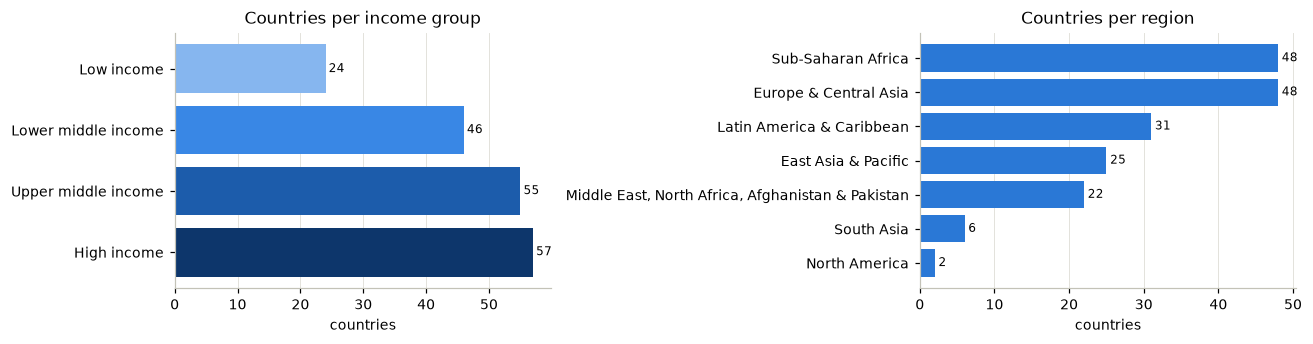

In [3]:
# Number of countries per income group and per region
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))

income_counts = clean["income_group"].value_counts().reindex(INCOME_ORDER)
axes[0].barh(income_counts.index, income_counts.values, color=[INCOME_COLORS[g] for g in income_counts.index])
axes[0].set_title("Countries per income group")
axes[0].invert_yaxis()

region_counts = clean["region"].value_counts().sort_values()
axes[1].barh(region_counts.index, region_counts.values, color="#2a78d6")
axes[1].set_title("Countries per region")

for ax, counts in ((axes[0], income_counts), (axes[1], region_counts)):
    ax.grid(axis="y", visible=False)
    for i, v in enumerate(counts.values):          # value at the end of each bar
        ax.text(v + 0.5, i, str(v), va="center", fontsize=8)
    ax.set_xlabel("countries")
plt.tight_layout()
plt.show()

**Result.**
- All four income groups are well represented: 57 high-income, 55 upper-middle, 46 lower-middle and 24 low-income countries. Low-income countries are the smallest group, but with 24 countries still large enough for comparisons.
- Sub-Saharan Africa and Europe & Central Asia contribute 48 countries each; **South Asia (6) and North America (2) are small**. Regional comparisons are therefore only meaningful for the large regions, which is why the following charts use income groups instead of regions.

## 2 Health systems and outcomes by income group
Six key indicators are compared across the four income groups with **box plots**. A box covers the middle 50% of the countries (interquartile range), the white line is the median, the whiskers show the range without outliers, and circles are outliers. Strongly skewed indicators (under-5 mortality, health spending, doctors) are shown on a **logarithmic axis**, so that both low and high values are readable.

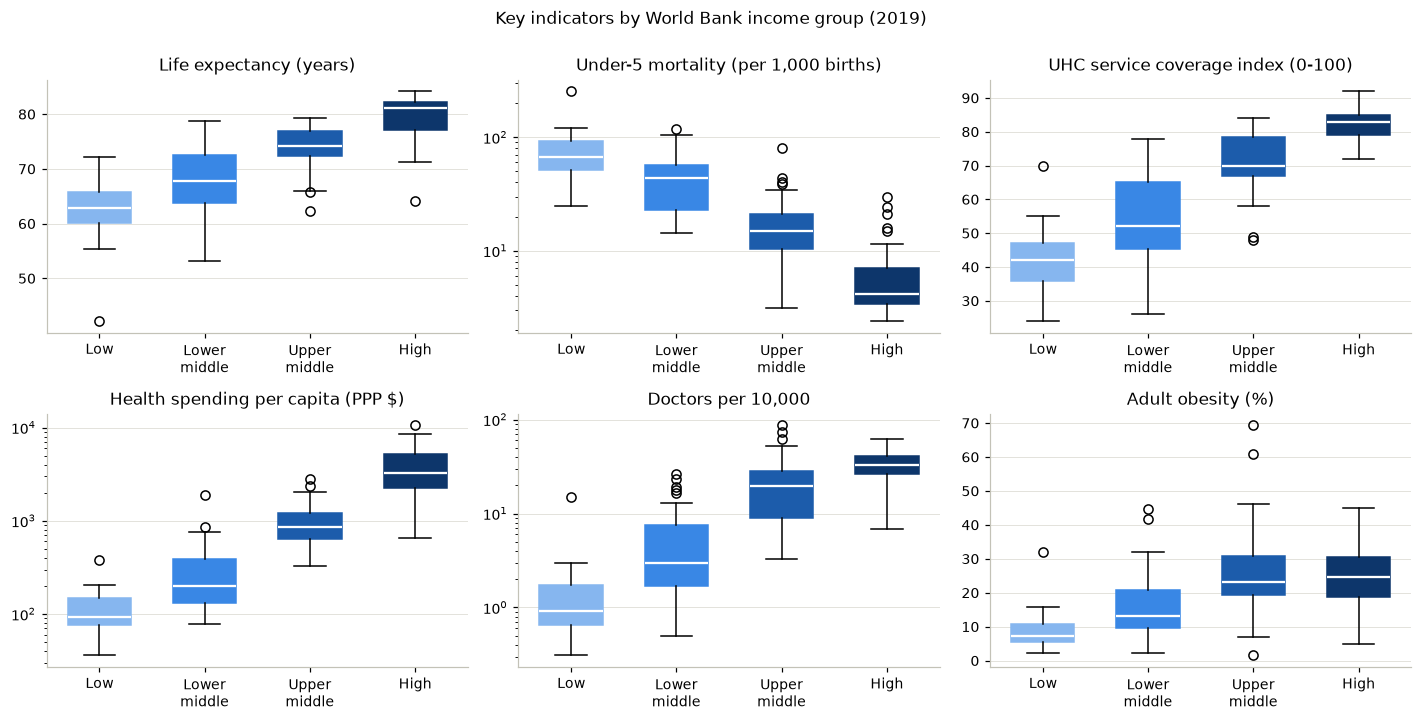

,life_expectancy,under5_mortality,uhc_index,health_exp_pc_ppp,doctors_per10k,obesity_prevalence
income_group,,,,,,
Low income,62.8,66.8,42.0,91.8,0.9,7.2
Lower middle income,67.8,43.8,52.0,198.7,2.9,13.3
Upper middle income,74.1,14.9,70.0,863.4,19.5,23.1
High income,81.2,4.2,83.0,3228.7,32.7,24.5


In [4]:
# Key indicators by income group (one box per income group)
key = {
    "life_expectancy": "Life expectancy (years)",
    "under5_mortality": "Under-5 mortality (per 1,000 births)",
    "uhc_index": "UHC service coverage index (0-100)",
    "health_exp_pc_ppp": "Health spending per capita (PPP $)",
    "doctors_per10k": "Doctors per 10,000",
    "obesity_prevalence": "Adult obesity (%)",
}
log_scale = {"under5_mortality", "health_exp_pc_ppp", "doctors_per10k"}   # strongly skewed -> log axis

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (col, title) in zip(axes.ravel(), key.items()):
    groups = [clean.loc[clean["income_group"] == g, col] for g in INCOME_ORDER]
    box = ax.boxplot(groups, patch_artist=True, widths=0.6, medianprops={"color": "white", "linewidth": 1.5})
    for patch, g in zip(box["boxes"], INCOME_ORDER):
        patch.set_facecolor(INCOME_COLORS[g])
        patch.set_edgecolor(INCOME_COLORS[g])
    ax.set_xticks(range(1, 5), ["Low", "Lower\nmiddle", "Upper\nmiddle", "High"])
    ax.set_title(title)
    if col in log_scale:
        ax.set_yscale("log")
    ax.grid(axis="x", visible=False)
fig.suptitle("Key indicators by World Bank income group (2019)", y=1.0)
plt.tight_layout()
plt.show()

# Median per income group as a table
clean.groupby("income_group")[list(key)].median().reindex(INCOME_ORDER).round(1)

**Result.** Almost every indicator follows a steep **income gradient**:

| Indicator | Low income | High income | Ratio |
|---|---|---|---|
| Life expectancy | 62.8 years | 81.2 years | +18 years |
| Under-5 mortality | 66.8 per 1,000 | 4.2 per 1,000 | 16× higher in low income |
| UHC service coverage | 42 | 83 | about half |
| Health spending per capita | 92 PPP $ | 3,229 PPP $ | 35× |
| Doctors per 10,000 | 0.9 | 32.7 | 36× |

**Observations**
- **Health spending and doctors** differ by a factor of about 35 between low- and high-income countries – much more than life expectancy (factor 1.3). Health-system *inputs* are far more unequal than health *outcomes*.
- **Obesity** is the exception: it rises from low to upper-middle income and then flattens (upper-middle 23%, high 25%). Risk factors of the "rich" type (obesity, physical inactivity) are already fully present in middle-income countries.
- Within each income group the spread is large (e.g. UHC 26–78 in lower-middle income). This is what makes the analysis interesting: countries at the same income level achieve very different coverage and outcomes.
- The low outlier in life expectancy (42 years) is the **Central African Republic**; its 2019 values are discussed in Section 8.

## 3 Causes of death and wealth

### 3.1 Mortality profile by income group
WHO groups all causes of death into three broad groups:
- **communicable, maternal, perinatal and nutritional conditions** (infections, deaths around birth, malnutrition),
- **noncommunicable diseases** (cardiovascular diseases, cancers, diabetes, chronic respiratory diseases, …),
- **injuries** (road injuries, violence, self-harm, …).

For each country the share of each group in all age-standardised deaths is calculated, and the shares are averaged per income group.

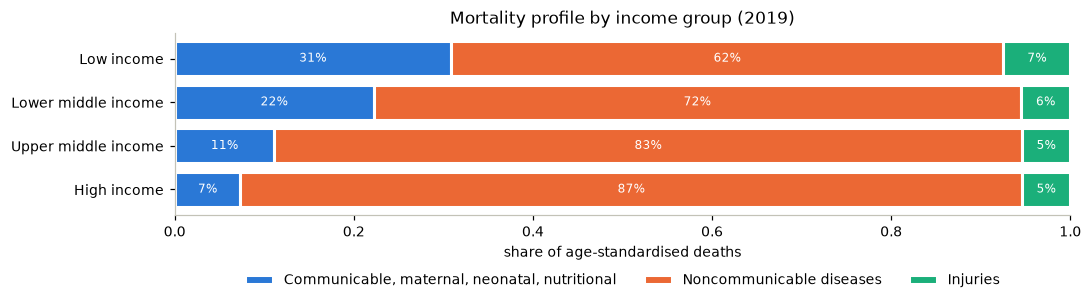

,"Communicable, maternal, neonatal, nutritional",Noncommunicable diseases,Injuries
income_group,,,
Low income,0.308,0.617,0.075
Lower middle income,0.222,0.723,0.055
Upper middle income,0.111,0.835,0.054
High income,0.073,0.873,0.054


In [ ]:
# Relative contribution of the three major cause groups
# to the total age-standardised mortality rate in 2019.
# These ratios do not represent shares of actual death counts.
# The broad groups are not in the clean file (only detailed causes), so they are taken from the full panel.
broad = {
    "death_asdr_communicable_maternal_perinatal_and_nutritional_conditions": "Communicable, maternal, neonatal, nutritional",
    "death_asdr_noncommunicable_diseases": "Noncommunicable diseases",
    "death_asdr_injuries": "Injuries",
}
y2019 = full[(full["year"] == 2019) & full["iso3"].isin(clean["iso3"])].set_index("iso3")
shares = y2019[list(broad)].div(y2019["death_asdr_all_causes"], axis=0).rename(columns=broad)
shares["income_group"] = clean.set_index("iso3")["income_group"]

profile = shares.groupby("income_group")[list(broad.values())].mean().reindex(INCOME_ORDER)

# 100% stacked horizontal bars: one bar per income group
fig, ax = plt.subplots(figsize=(10, 3))
left = np.zeros(len(profile))
for (name, values), color in zip(profile.items(), CATEGORY_COLORS):
    ax.barh(profile.index, values, left=left, color=color, label=name, edgecolor="white", linewidth=2)
    for i, (l, v) in enumerate(zip(left, values)):
        ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white", fontsize=8)
    left += values.values
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of age-standardised deaths")
ax.grid(visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
ax.set_title("Mortality profile by income group (2019)")
plt.tight_layout()
plt.show()
profile.round(3)

**Result.** The share of **communicable diseases falls from 31% in low-income to 7% in high-income countries**, while the share of **noncommunicable diseases rises from 62% to 87%**. Injuries stay at 5–7% in all groups.

Even in low-income countries, noncommunicable diseases cause the majority of (age-standardised) deaths. Poor countries are therefore not "infection-only" countries; they carry a **double burden** of communicable and noncommunicable diseases.

### 3.2 Epidemiological transition
The *epidemiological transition* describes the shift from infectious to chronic diseases as countries develop. The scatter plot shows the share of noncommunicable deaths against GDP per capita (log scale) for every country.

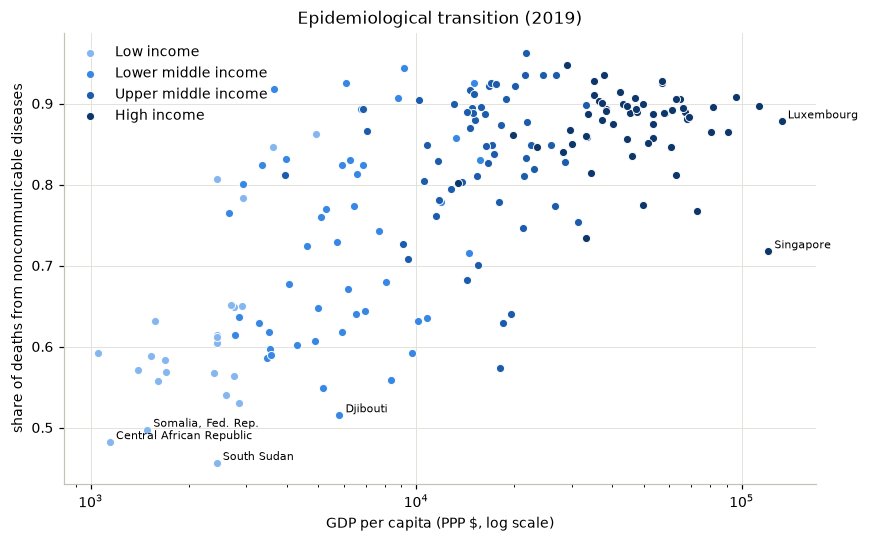

Spearman correlation GDP per capita vs. NCD share: 0.65


In [6]:
# Epidemiological transition: share of noncommunicable deaths vs. GDP per capita
ncd_share = shares["Noncommunicable diseases"]
gdp = clean.set_index("iso3")["gdp_pc_ppp"]

fig, ax = plt.subplots(figsize=(8, 5))
for g in INCOME_ORDER:
    idx = shares.index[shares["income_group"] == g]
    ax.scatter(gdp[idx], ncd_share[idx], s=28, color=INCOME_COLORS[g], label=g, edgecolor="white", linewidth=0.6)
ax.set_xscale("log")
ax.set_xlabel("GDP per capita (PPP $, log scale)")
ax.set_ylabel("share of deaths from noncommunicable diseases")
ax.set_title("Epidemiological transition (2019)")
ax.legend(frameon=False)

# label a few extreme countries
names = clean.set_index("iso3")["country"]
for iso in list(ncd_share.nsmallest(4).index) + list(gdp.nlargest(2).index):
    ax.annotate(names[iso], (gdp[iso], ncd_share[iso]), fontsize=7, xytext=(4, 2), textcoords="offset points")
plt.tight_layout()
plt.show()

rho = pd.Series(gdp).corr(ncd_share, method="spearman")
print(f"Spearman correlation GDP per capita vs. NCD share: {rho:.2f}")

**Result.** There is a clear positive relationship (Spearman ρ = 0.65): richer countries have a higher share of noncommunicable deaths.

**Observations**
- Below about 3,000 PPP $ per capita, NCD shares range from 46% (South Sudan) to over 80%. At low income the variation is largest, because conflict, HIV and malaria burden differ strongly between countries.
- Above about 20,000 PPP $ the curve flattens at 85–95%: the transition is complete.
- Some high-income countries lie lower, e.g. **Singapore** (72%): there **lower respiratory infections** (pneumonia) are the leading cause of death (137 per 100,000), ahead of ischaemic heart disease.
- The countries with the lowest NCD share (South Sudan, Central African Republic, Somalia) are all **conflict-affected**. This suggests that conflict is an important driver of the mortality profile, besides income.

### 3.3 Top 10 causes of death per income group
The ten detailed causes with the highest median death rate (per 100,000, age-standardised) in each income group.

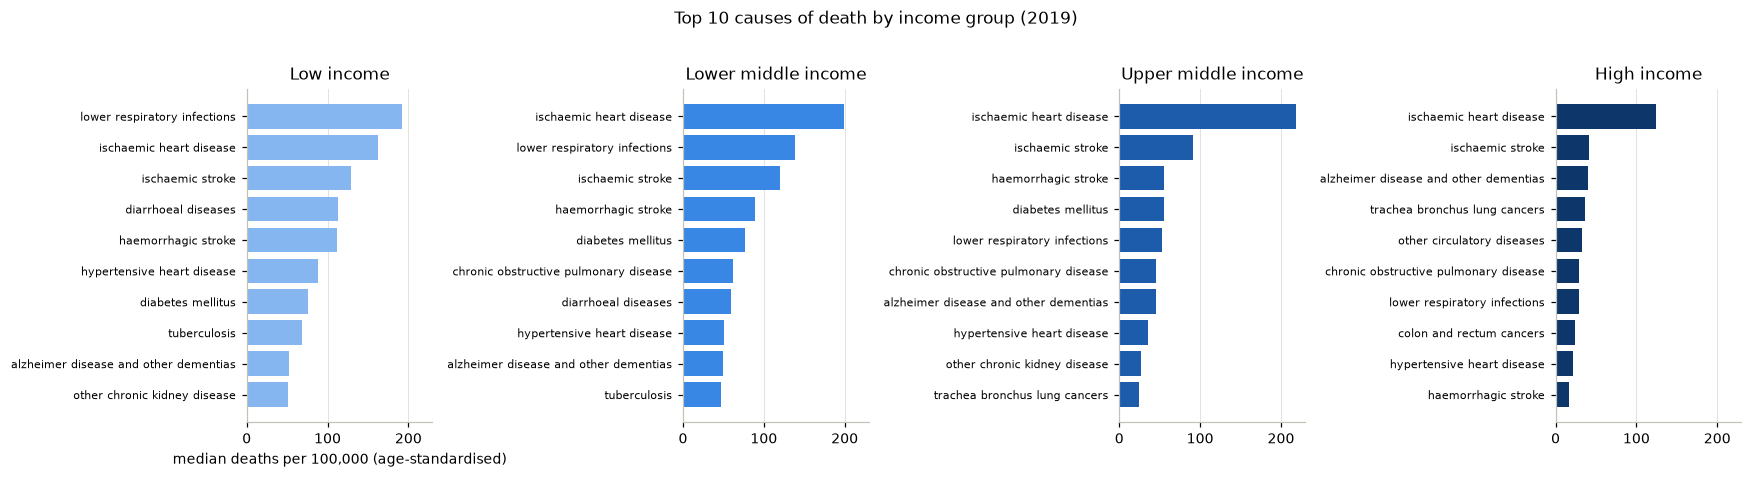

In [7]:
# Ten causes with the highest median death rate in each income group (detailed causes only)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True)
for ax, g in zip(axes, INCOME_ORDER):
    top = clean.loc[clean["income_group"] == g, cause_cols].median().nlargest(10).sort_values()
    ax.barh([label(c) for c in top.index], top.values, color=INCOME_COLORS[g])
    ax.set_title(g)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=7)
axes[0].set_xlabel("median deaths per 100,000 (age-standardised)")
fig.suptitle("Top 10 causes of death by income group (2019)", y=1.02)
plt.tight_layout()
plt.show()

**Result.**
- **Ischaemic heart disease** is the first or second cause of death in every income group – cardiovascular disease is truly global.
- In **low-income** countries, **lower respiratory infections** (pneumonia) rank first, and **diarrhoeal diseases** and **tuberculosis** are in the top 10.
- In **high-income** countries, the top 10 consists only of noncommunicable diseases: dementia, lung cancer and colorectal cancer appear, typical diseases of ageing populations.
- The absolute level drops strongly with income: the leading cause in low-income countries (lower respiratory infections, ~190 per 100,000) is higher than the leading cause in high-income countries (ischaemic heart disease, ~125 per 100,000). Rich countries have lower rates for almost every cause, not only for infections.

## 4 Correlations between indicators

### 4.1 Correlation matrix
The Spearman correlation between all 71 indicators. The rows and columns are **ordered by hierarchical clustering** (average linkage), so that indicators with similar correlation patterns are placed next to each other and blocks of related indicators become visible. Red = positive, blue = negative correlation.

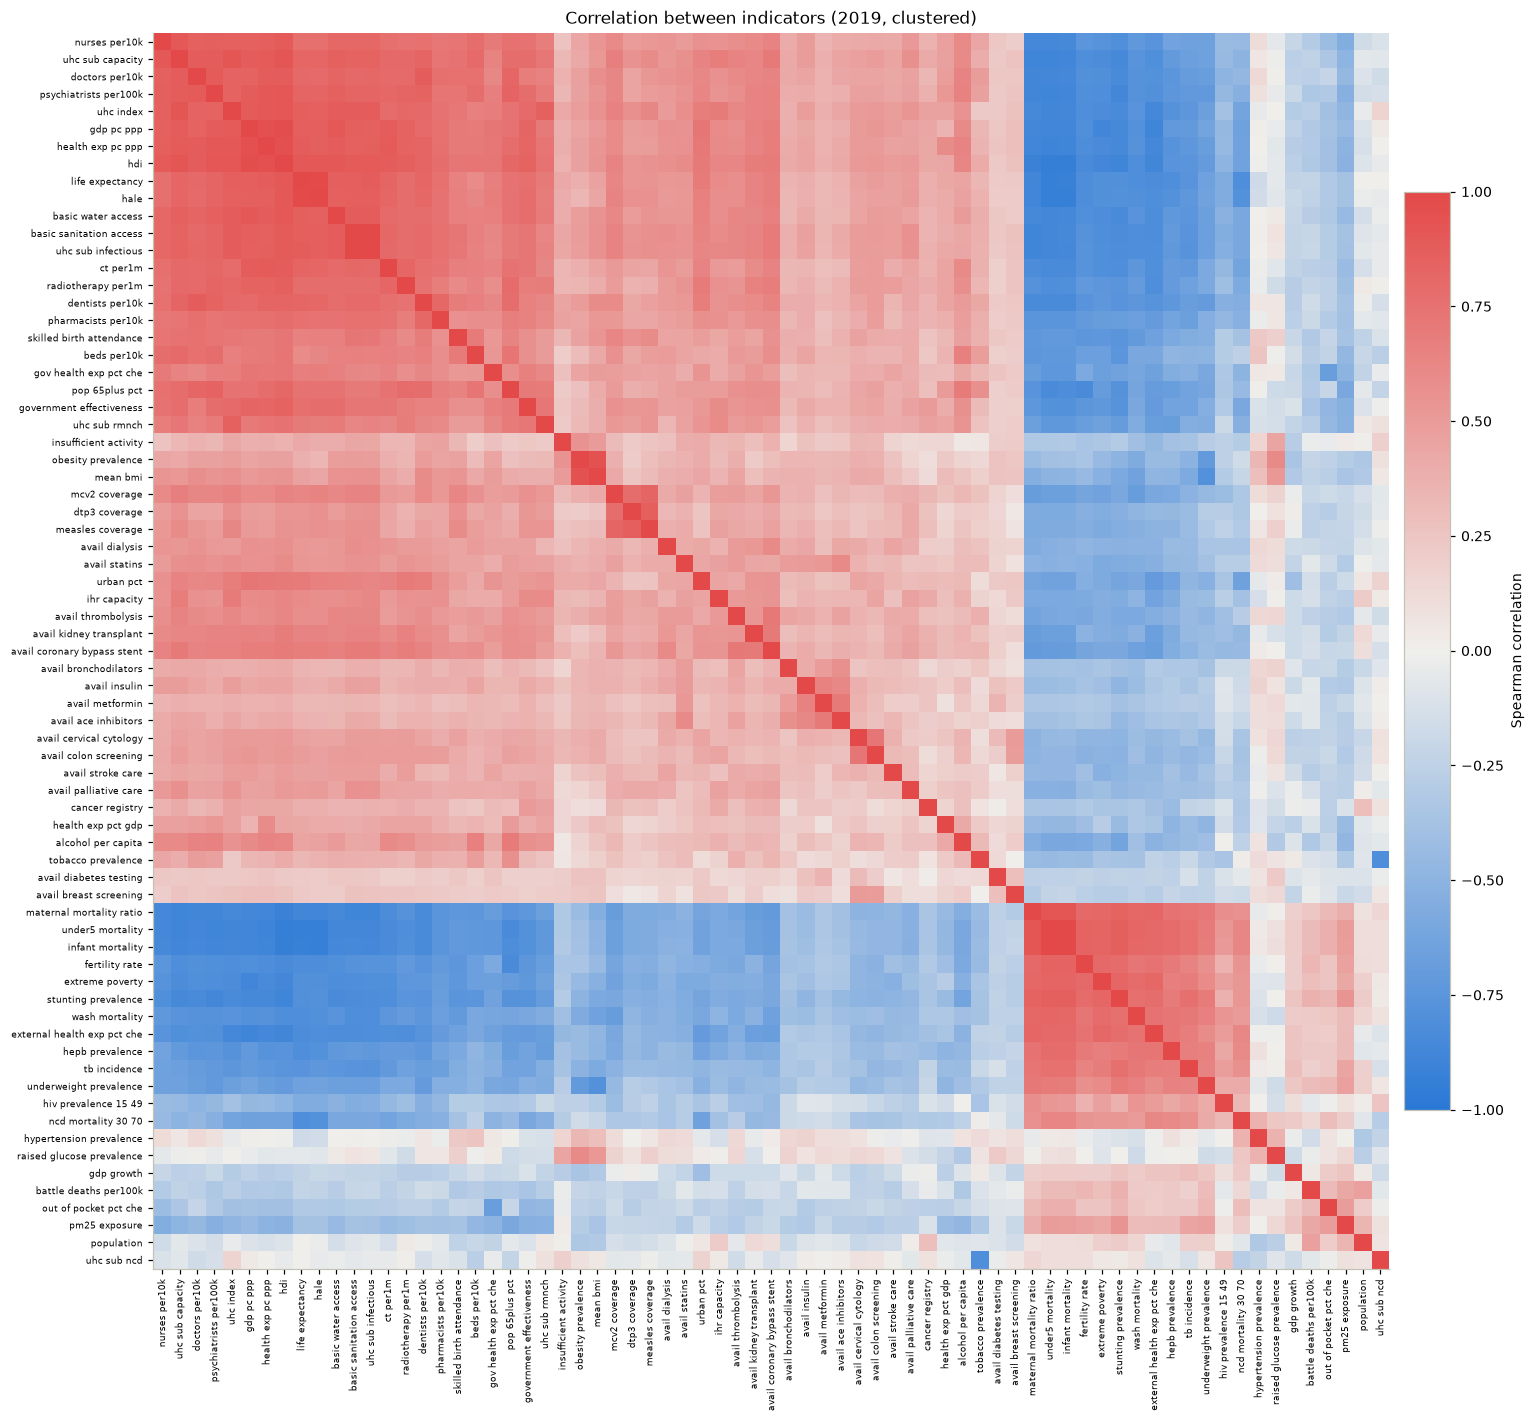

In [8]:
# Spearman correlation between all indicators, ordered by hierarchical clustering
# (similar indicators end up next to each other, so blocks of related indicators become visible)
corr_ind = clean[indicator_cols].corr(method="spearman")
order = leaves_list(linkage(corr_ind.values, method="average"))
corr_ind_ordered = corr_ind.iloc[order, order]

fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(corr_ind_ordered, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), [label(c) for c in corr_ind_ordered.columns], rotation=90, fontsize=6)
ax.set_yticks(range(len(order)), [label(c) for c in corr_ind_ordered.index], fontsize=6)
ax.grid(visible=False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01, label="Spearman correlation")
ax.set_title("Correlation between indicators (2019, clustered)")
plt.tight_layout()
plt.show()

**Result.** The matrix has a very clear structure:

1. **A large red "development" block** (top left): health workforce (nurses, doctors, psychiatrists, dentists, pharmacists), UHC coverage, GDP, health spending, HDI, life expectancy, water and sanitation, medical devices, government effectiveness and the share of people aged 65+. All of these increase together with development.
2. **A large blue block** against it: child and maternal mortality, fertility, poverty, stunting, TB incidence, unsafe-water mortality, external (donor) health financing and underweight. These are high exactly where the first block is low.
3. **Weaker, separate groups**:
   - the **treatment-availability** indicators correlate only moderately with the rest (mostly 0.2–0.5). Whether insulin or dialysis is available is related to wealth, but far from determined by it;
   - **metabolic risk factors** (obesity, mean BMI, raised glucose, hypertension) form their own small cluster and are only weakly related to the development block;
   - **out-of-pocket spending, PM2.5, battle deaths, GDP growth and population** are only weakly related to the rest.

**Interpretation.** Most of the variation between countries runs along **one development axis**. This is confirmed by the PCA in Section 7 and is the main challenge for the network: almost everything is correlated with everything through wealth.

### 4.2 Strongest indicator pairs
Pairs of indicators with |ρ| ≥ 0.9 measure (almost) the same thing for the purpose of a cross-country comparison. If both were used as network nodes, they would produce trivial edges.

In [9]:
# Strongest indicator pairs (|rho| >= 0.9): candidates for redundancy
pairs = (corr_ind.where(np.triu(np.ones(corr_ind.shape, dtype=bool), k=1))   # upper triangle only
         .stack().rename("spearman").reset_index())
pairs.columns = ["indicator_a", "indicator_b", "spearman"]
pairs = pairs[pairs["spearman"].abs() >= 0.9].sort_values("spearman", key=abs, ascending=False)
print(len(pairs), "indicator pairs with |rho| >= 0.9")
pairs.round(3)

24 indicator pairs with |rho| >= 0.9


,indicator_a,indicator_b,spearman
577,under5_mortality,infant_mortality,0.995
1121,basic_sanitation_access,uhc_sub_infectious,0.993
1801,life_expectancy,hale,0.992
1206,gdp_pc_ppp,hdi,0.965
87,health_exp_pc_ppp,gdp_pc_ppp,0.952
141,health_exp_pc_ppp,hdi,0.951
4466,obesity_prevalence,mean_bmi,0.944
638,under5_mortality,hdi,-0.936
709,infant_mortality,hdi,-0.932
594,under5_mortality,hale,-0.928


**Result.** 24 pairs have |ρ| ≥ 0.9. The near-identical ones (|ρ| > 0.95) are:
- **under-5 vs. infant mortality** (0.995) – infant deaths are a large part of under-5 deaths,
- **basic sanitation vs. UHC infectious-disease sub-index** (0.993) – basic sanitation is one of the tracer indicators *inside* this sub-index,
- **life expectancy vs. healthy life expectancy** (0.992),
- **GDP per capita vs. HDI** (0.965) and **health spending vs. GDP** (0.952) – HDI contains income, and health spending is largely a function of income.

**Decision.** For the network one indicator of each near-identical pair is used (see Section 9). Composite indices (UHC, HDI) should not be used together with their own components.

### 4.3 Average correlation between indicator groups
To summarise the matrix, the average absolute correlation within and between the indicator groups is calculated (diagonal = within a group).

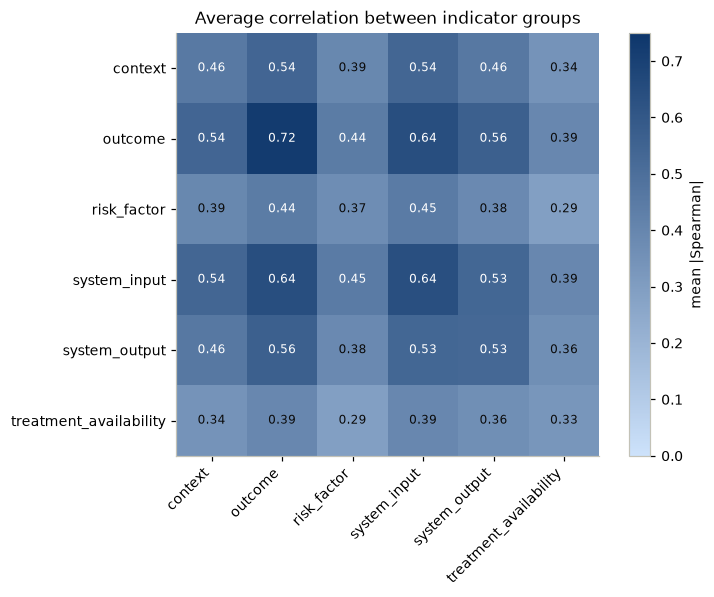

In [10]:
# Average absolute correlation between indicator groups: how strongly is each group tied to the others?
groups = pd.Series({c: group_of[c] for c in indicator_cols})
group_names = sorted(groups.unique())
block = pd.DataFrame(index=group_names, columns=group_names, dtype=float)
for a in group_names:
    for b in group_names:
        sub = corr_ind.loc[groups[groups == a].index, groups[groups == b].index].abs()
        if a == b:   # within a group: ignore the diagonal (correlation of a column with itself)
            sub = sub.where(~np.eye(len(sub), dtype=bool))
        block.loc[a, b] = np.nanmean(sub.values)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(block.astype(float), cmap=LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#0d366b"]), vmin=0, vmax=0.75)
ax.set_xticks(range(len(group_names)), group_names, rotation=45, ha="right")
ax.set_yticks(range(len(group_names)), group_names)
for i in range(len(group_names)):
    for j in range(len(group_names)):
        v = block.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.4 else "#0b0b0b")
ax.grid(visible=False)
fig.colorbar(im, ax=ax, fraction=0.04, label="mean |Spearman|")
ax.set_title("Average correlation between indicator groups")
plt.tight_layout()
plt.show()

**Result.**
- **Outcomes** are most strongly related to **system inputs** (0.64) and **context** (0.54), and somewhat less to **system outputs** (0.56). Health-system resources and wealth are both closely tied to outcomes.
- **Treatment availability** has the weakest links to all other groups (0.29–0.39). It adds information that is *not* already contained in wealth or spending – useful for the network, because it can show specific links (e.g. dialysis ↔ kidney disease) instead of the general development effect.
- **Risk factors** are also only moderately linked (0.37–0.45): they are a heterogeneous group (obesity rises with wealth, underweight and stunting fall with it).

## 5 Causes of death vs. health-system coverage

Almost all causes of death are correlated with GDP. The central question of the project is whether the **health system** explains differences in mortality **beyond wealth**. To separate the two, each cause is placed in a scatter plot:

- **x-axis**: Spearman correlation of the cause with **GDP per capita**,
- **y-axis**: **partial Spearman correlation** of the cause with the **UHC service coverage index**, *controlling for GDP*.

The **partial correlation** answers: *among countries with similar GDP, do countries with higher health-service coverage have fewer deaths from this cause?* It is computed by ranking all variables, removing the part of each rank that is explained by the GDP rank (linear regression), and correlating what is left (the residuals).

How to read the plot:
- **bottom left**: causes that are lower in rich countries **and** lower where coverage is high, even at the same GDP → *healthcare-sensitive* causes,
- **near y = 0**: causes related to wealth, but not to coverage beyond wealth,
- **top right**: causes that are higher in rich countries and in countries with high coverage.

### Partial Spearman Correlation

To examine the relationship between health-system indicators and cause-specific mortality beyond national wealth, we calculate partial Spearman correlations while controlling for GDP per capita.

This analysis identifies statistical associations after adjusting for GDP, but does not establish causal relationships.

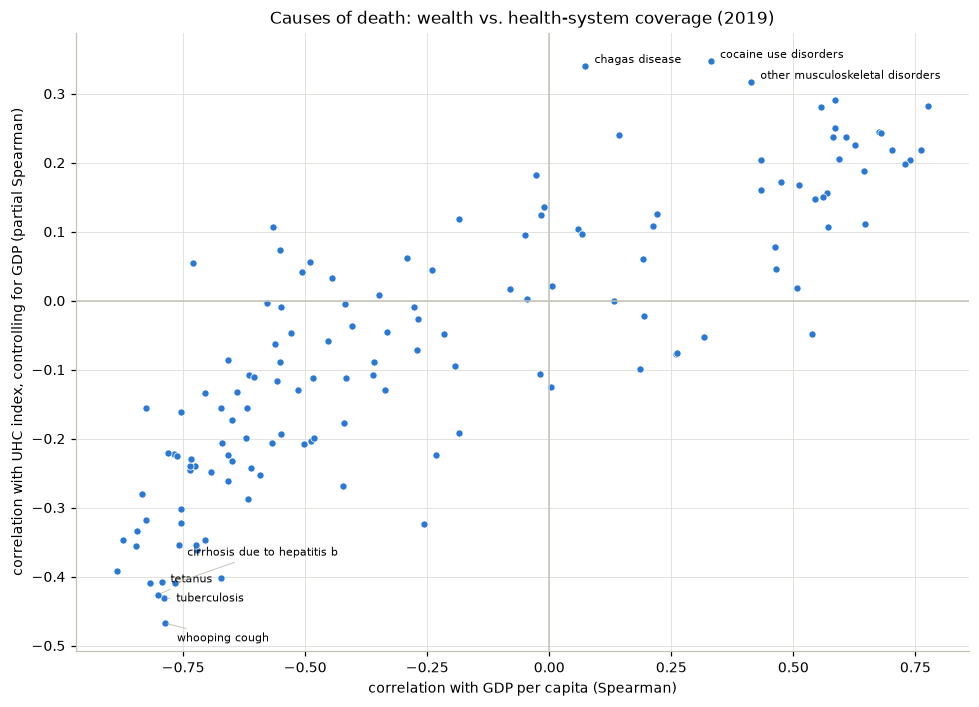

Most negative partial correlation with UHC (fewer deaths where coverage is higher, beyond GDP):
                              rho_gdp  partial_rho_uhc
whooping cough                  -0.79            -0.47
tuberculosis                    -0.79            -0.43
tetanus                         -0.80            -0.43
cirrhosis due to hepatitis b    -0.77            -0.41
diphtheria                      -0.82            -0.41
syphilis                        -0.79            -0.41
measles                         -0.67            -0.40
maternal conditions             -0.89            -0.39
malaria                         -0.72            -0.36
preterm birth complications     -0.85            -0.36


In [11]:
# Which causes of death are related to the health system beyond national wealth?
# For each cause:
#   x = Spearman correlation with GDP per capita
#   y = partial Spearman correlation with the UHC index, controlling for GDP per capita
# Partial correlation: rank all variables, remove the linear effect of GDP from both ranks, correlate the residuals.


def partial_spearman(x, y, control):
    """Spearman correlation of x and y after removing the effect of a control variable.

    Parameters
    x, y, control: pandas.Series (same index)

    Returns
    float, correlation of the rank residuals
    """
    rx, ry, rc = x.rank(), y.rank(), control.rank()
    res_x = rx - np.polyval(np.polyfit(rc, rx, 1), rc)   # part of x not explained by the control
    res_y = ry - np.polyval(np.polyfit(rc, ry, 1), rc)   # part of y not explained by the control
    return np.corrcoef(res_x, res_y)[0, 1]


sensitivity = pd.DataFrame({
    "rho_gdp": [clean[c].corr(clean["gdp_pc_ppp"], method="spearman") for c in cause_cols],
    "partial_rho_uhc": [partial_spearman(clean[c], clean["uhc_index"], clean["gdp_pc_ppp"]) for c in cause_cols],
}, index=[label(c) for c in cause_cols])

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(sensitivity["rho_gdp"], sensitivity["partial_rho_uhc"], s=22, color="#2a78d6", edgecolor="white", linewidth=0.5)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.axvline(0, color="#c3c2b7", linewidth=1)
# label the 4 most negative and 3 most positive causes (offsets chosen so labels do not overlap)
to_label = list(sensitivity["partial_rho_uhc"].nsmallest(4).index) + list(sensitivity["partial_rho_uhc"].nlargest(3).index)
offsets = [(8, -12), (8, -2), (8, 8), (8, 18), (6, 2), (6, 2), (6, 2)]
for name, offset in zip(to_label, offsets):
    ax.annotate(name, (sensitivity.loc[name, "rho_gdp"], sensitivity.loc[name, "partial_rho_uhc"]),
                fontsize=7, xytext=offset, textcoords="offset points",
                arrowprops={"arrowstyle": "-", "color": "#c3c2b7", "linewidth": 0.6})
ax.set_xlabel("correlation with GDP per capita (Spearman)")
ax.set_ylabel("correlation with UHC index, controlling for GDP (partial Spearman)")
ax.set_title("Causes of death: wealth vs. health-system coverage (2019)")
plt.tight_layout()
plt.show()

print("Most negative partial correlation with UHC (fewer deaths where coverage is higher, beyond GDP):")
print(sensitivity.sort_values("partial_rho_uhc").head(10).round(2).to_string())

**Result.**
- The causes with the most negative partial correlation (−0.36 to −0.47) are **whooping cough, tuberculosis, tetanus, diphtheria, measles, syphilis, cirrhosis due to hepatitis B, maternal conditions, malaria and preterm birth complications**. These are exactly the causes that well-known health services prevent: **vaccination** (whooping cough, tetanus, diphtheria, measles, hepatitis B), **TB treatment**, **antenatal and delivery care** (maternal conditions, preterm birth, congenital syphilis) and **malaria control**. This is strong evidence that the data contain a real health-system signal beyond wealth.
- On the top right are causes such as **cocaine and other drug use disorders, musculoskeletal disorders** and several cancers, which are higher in rich countries with high coverage. This is unlikely to mean that coverage causes these deaths. More plausible explanations are **better diagnosis and registration** in strong health systems and the fact that people survive long enough to die of these causes.
- Most causes lie on a diagonal: the stronger a cause is linked to poverty, the more it is also linked to low coverage beyond GDP.

**Caution.** These are correlations between countries in one year, not causal effects. The UHC index is itself built from service indicators (e.g. vaccination, TB treatment), so the result shows that *countries that deliver these services* have fewer deaths from the corresponding causes.

## 6 Correlations between causes of death

### 6.1 Raw correlation matrix
The Spearman correlation between all 139 causes, ordered by hierarchical clustering. Red blocks along the diagonal are groups of causes that are high in the same countries – a first look at the **disease communities** the network will detect.

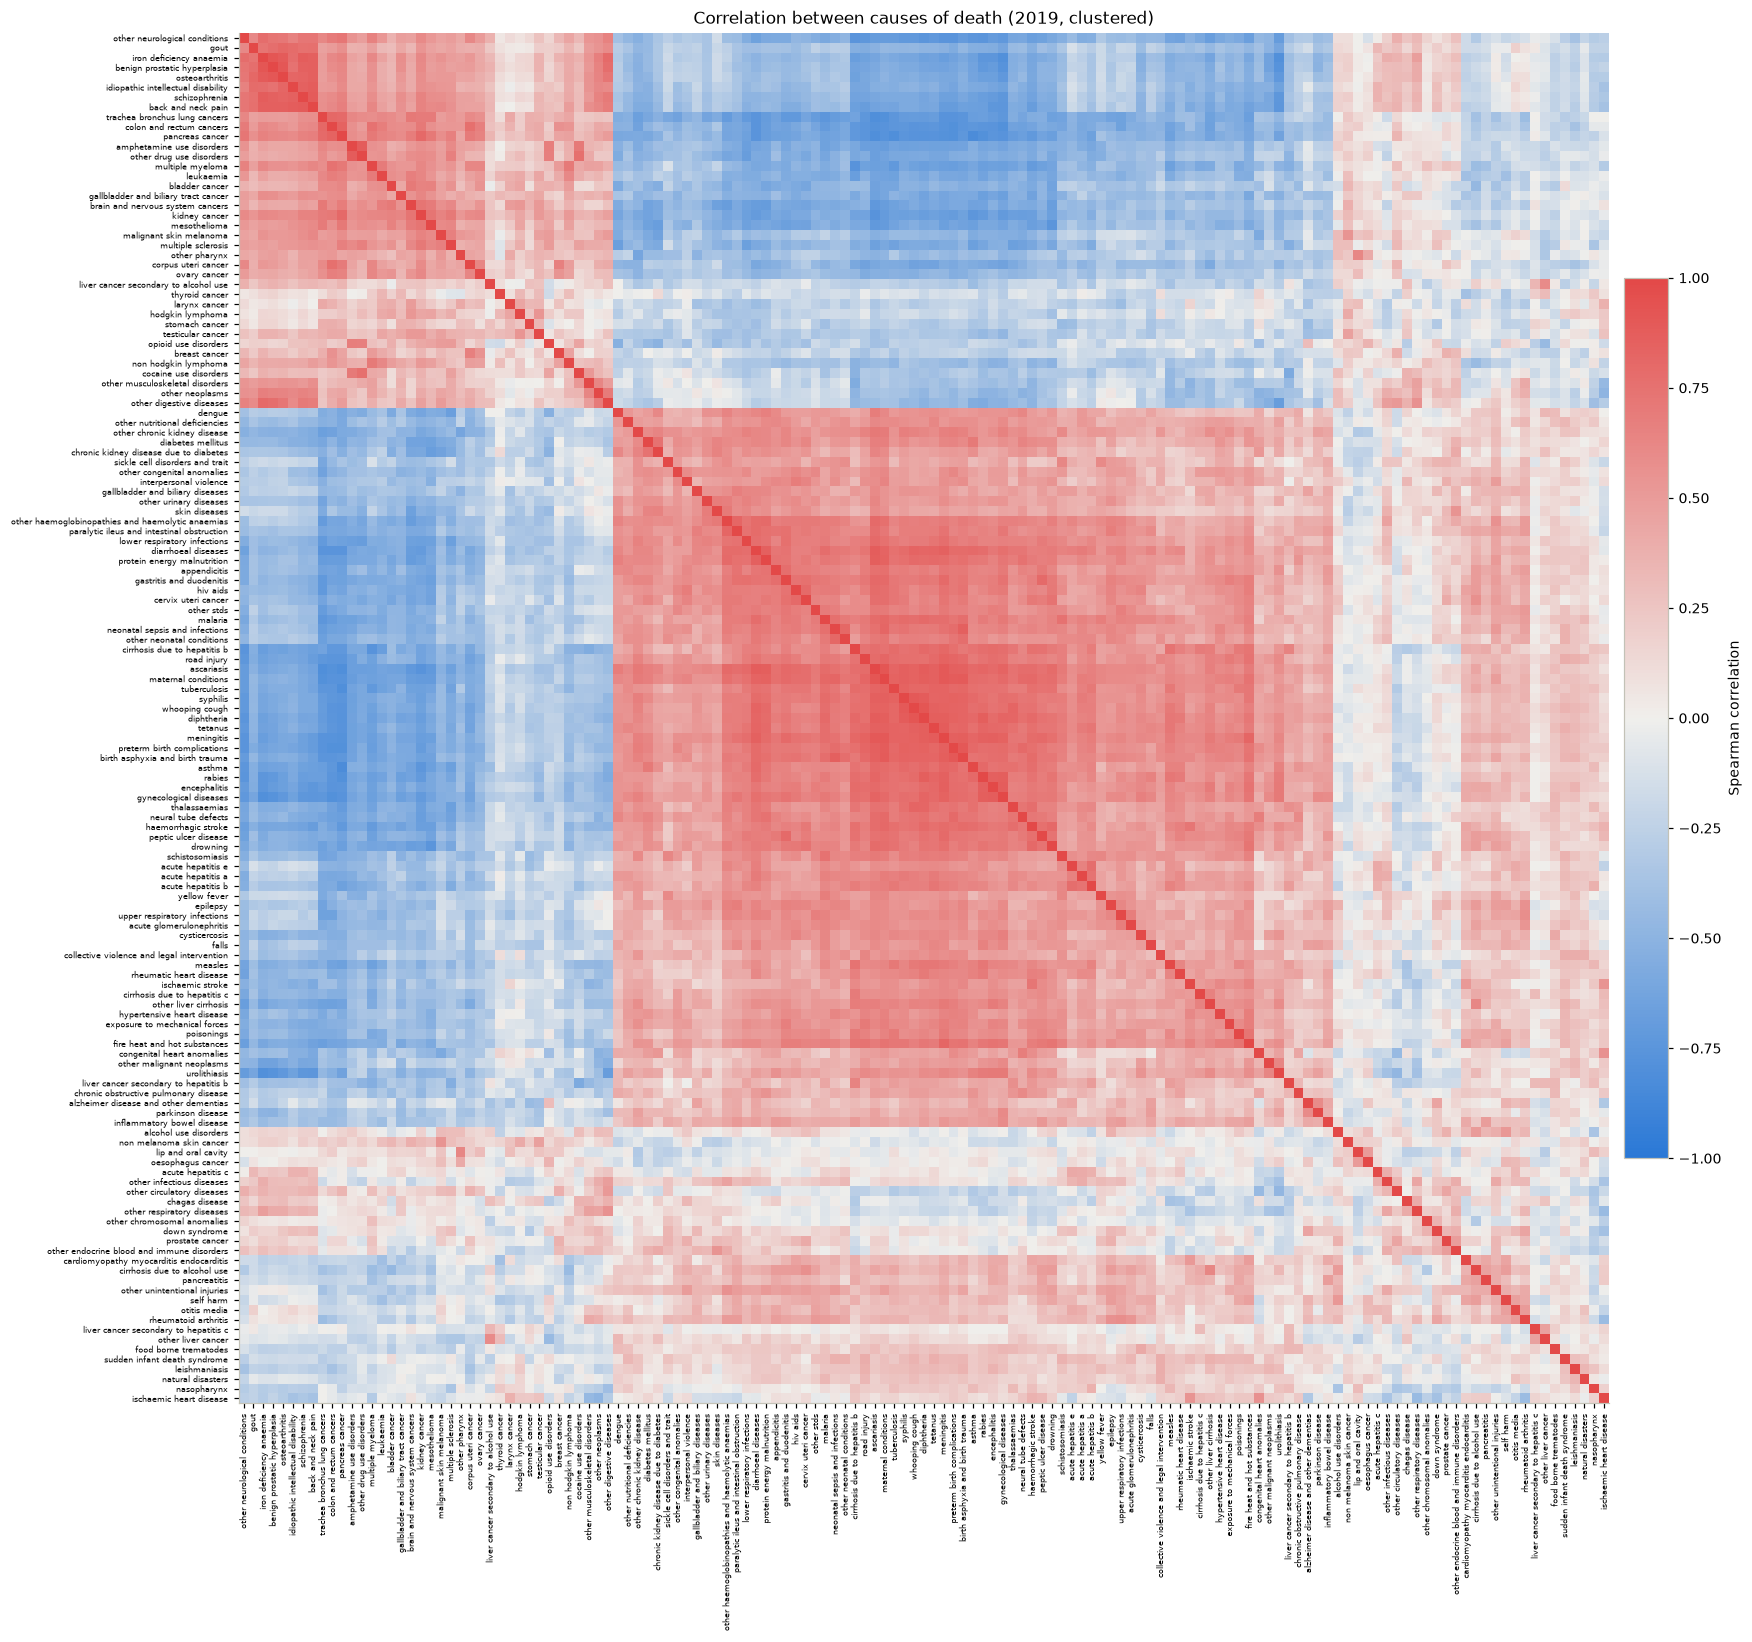

In [12]:
# Spearman correlation between the 139 causes of death, ordered by hierarchical clustering.
# Blocks of red along the diagonal = groups of causes that are high in the same countries
# (a first look at the disease communities the network will detect).
corr_causes = clean[cause_cols].corr(method="spearman")
link = linkage(corr_causes.values, method="average")
order_c = leaves_list(link)
corr_causes_ordered = corr_causes.iloc[order_c, order_c]

fig, ax = plt.subplots(figsize=(16, 15))
im = ax.imshow(corr_causes_ordered, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(order_c)), [label(c) for c in corr_causes_ordered.columns], rotation=90, fontsize=5)
ax.set_yticks(range(len(order_c)), [label(c) for c in corr_causes_ordered.index], fontsize=5)
ax.grid(visible=False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01, label="Spearman correlation")
ax.set_title("Correlation between causes of death (2019, clustered)")
plt.tight_layout()
plt.show()

**Result.** The matrix is dominated by **two large opposing blocks**:
- a **large "poverty" block** (centre): infections (TB, HIV, diarrhoea, malaria, childhood-cluster diseases), maternal and neonatal conditions, malnutrition, but also road injury, rheumatic heart disease, stroke and diabetes. These causes are high in the same (poor) countries;
- a **"rich-country" block** (top left): most cancers (lung, colorectal, pancreas, bladder, kidney, …), multiple sclerosis and drug use disorders.

The two blocks are negatively correlated with each other (blue). This is again the **development axis**: if a country is poor, almost all poverty-related causes are high and the "rich-country" causes are low. A network built on these raw correlations would mainly show this one axis.

### 6.2 Correlation matrix after removing GDP
To see the structure *beyond* wealth, the same partial-correlation approach as in Section 5 is applied to all causes: the effect of GDP per capita is removed from every cause, and the residuals are correlated.

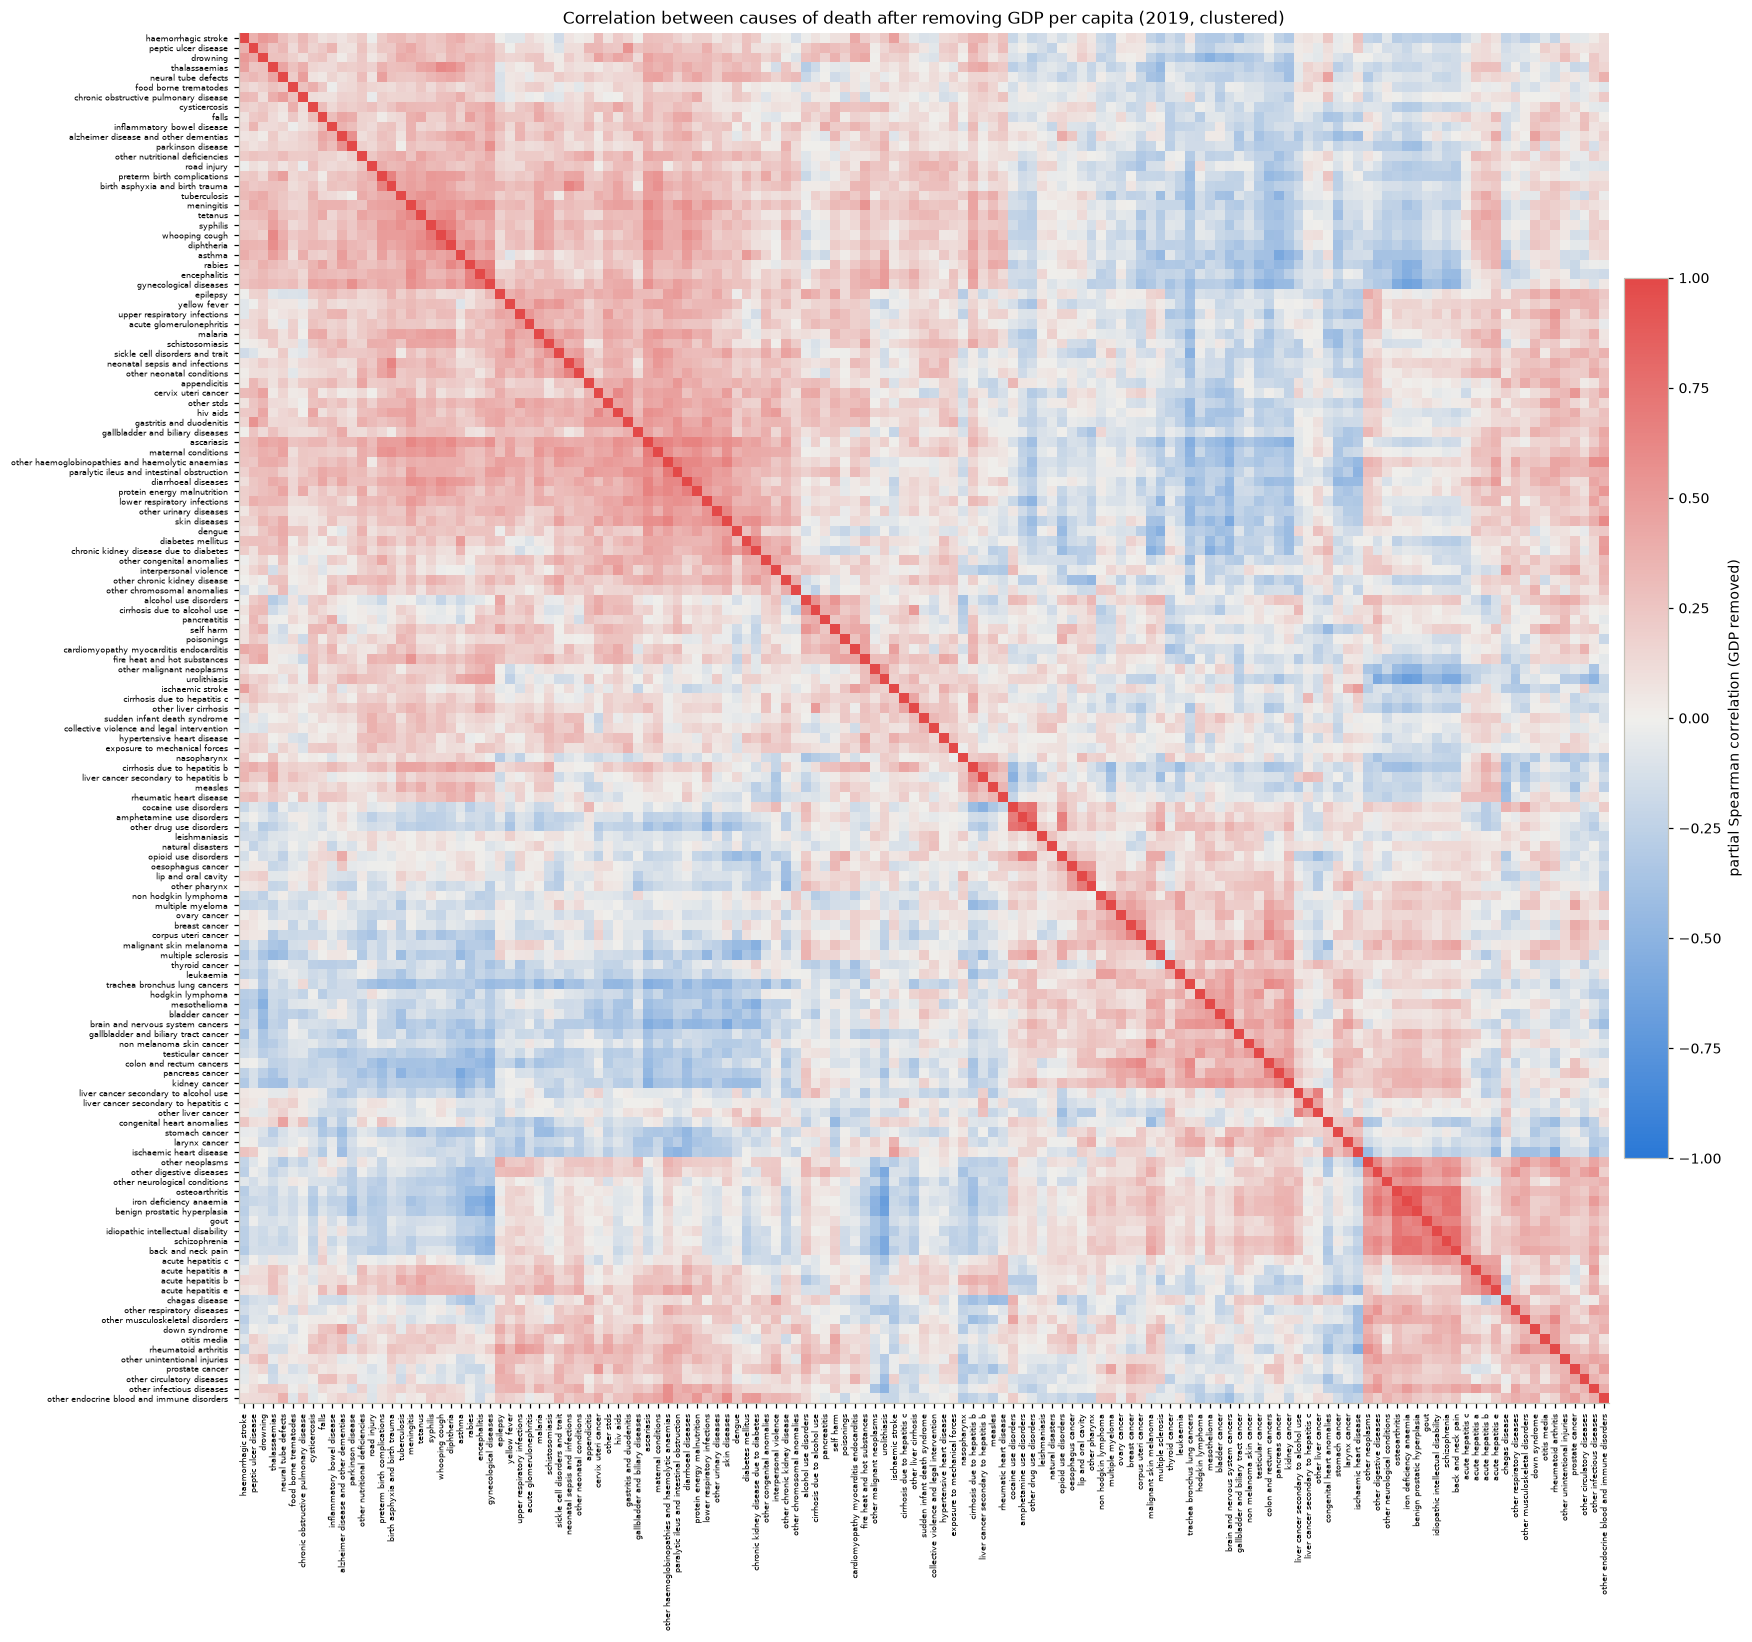

In [13]:
# The same correlation matrix after removing the effect of GDP per capita (partial Spearman correlation):
# every cause is ranked, the part explained by the GDP rank is removed, and the residuals are correlated.
gdp_rank = clean["gdp_pc_ppp"].rank()
residuals = pd.DataFrame({
    c: clean[c].rank() - np.polyval(np.polyfit(gdp_rank, clean[c].rank(), 1), gdp_rank) for c in cause_cols
})
corr_causes_adj = residuals.corr()
order_a = leaves_list(linkage(corr_causes_adj.values, method="average"))
corr_causes_adj_ordered = corr_causes_adj.iloc[order_a, order_a]

fig, ax = plt.subplots(figsize=(16, 15))
im = ax.imshow(corr_causes_adj_ordered, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(order_a)), [label(c) for c in corr_causes_adj_ordered.columns], rotation=90, fontsize=5)
ax.set_yticks(range(len(order_a)), [label(c) for c in corr_causes_adj_ordered.index], fontsize=5)
ax.grid(visible=False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01, label="partial Spearman correlation (GDP removed)")
ax.set_title("Correlation between causes of death after removing GDP per capita (2019, clustered)")
plt.tight_layout()
plt.show()

**Result.** After removing GDP the giant blocks dissolve into **smaller, more specific groups**, for example:
- **vaccine-preventable and infectious childhood diseases** (tetanus, diphtheria, whooping cough, meningitis, tuberculosis, syphilis, encephalitis) still cluster together – they share the same underlying cause: missing basic health services,
- **cancers** form their own block, with **drug use disorders** (cocaine, amphetamine, opioid) next to them,
- **hepatitis-related causes** group together: acute hepatitis A, B, C and E in one group, cirrhosis and liver cancer due to hepatitis B in another,
- a tight block of **osteoarthritis, gout, back and neck pain, benign prostatic hyperplasia, iron-deficiency anaemia, schizophrenia and intellectual disability**.

**Caution about the last block.** These causes almost never cause death directly (median 0 deaths, see the initial EDA). Their strong correlation is most likely an **artefact of how WHO estimates small death numbers** for such causes (similar modelling assumptions for all of them), not a real epidemiological connection. They should be interpreted carefully or excluded in a robustness check.

### 6.3 How much of the correlation is wealth?
The distribution of the correlations between all 9,591 pairs of causes, before and after removing GDP.

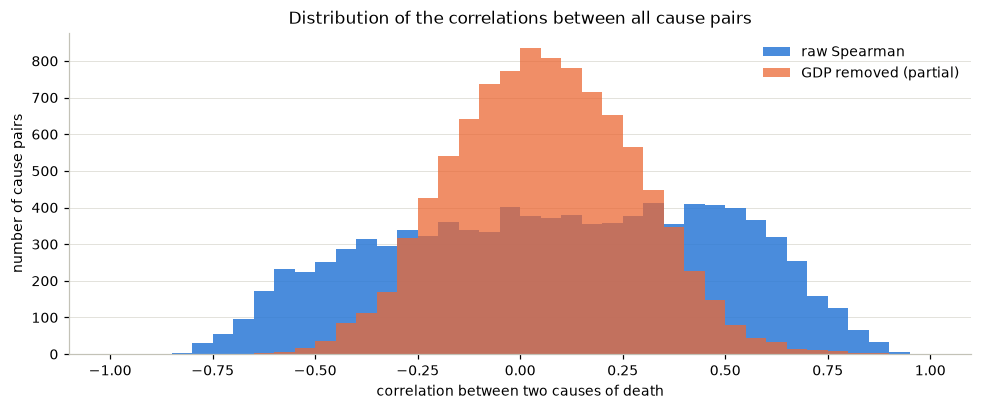

pairs with |rho| > 0.5: raw 27%, after removing GDP 2%
mean |rho|:             raw 0.34, after removing GDP 0.18


In [14]:
# How much of the correlation between causes is explained by wealth? Compare all pairs before and after.
upper = np.triu(np.ones(corr_causes.shape, dtype=bool), k=1)   # each pair once
raw_pairs = corr_causes.values[upper]
adj_pairs = corr_causes_adj.values[upper]

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(-1, 1, 41)
ax.hist(raw_pairs, bins=bins, color="#2a78d6", alpha=0.85, label="raw Spearman")
ax.hist(adj_pairs, bins=bins, color="#eb6834", alpha=0.75, label="GDP removed (partial)")
ax.set_xlabel("correlation between two causes of death")
ax.set_ylabel("number of cause pairs")
ax.set_title("Distribution of the correlations between all cause pairs")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"pairs with |rho| > 0.5: raw {np.mean(np.abs(raw_pairs) > 0.5):.0%}, after removing GDP {np.mean(np.abs(adj_pairs) > 0.5):.0%}")
print(f"mean |rho|:             raw {np.mean(np.abs(raw_pairs)):.2f}, after removing GDP {np.mean(np.abs(adj_pairs)):.2f}")

**Result.**
- Before adjustment, **27% of all cause pairs** have a correlation stronger than ±0.5; the distribution is wide and bimodal (two humps at about −0.5 and +0.5, i.e. "same side" vs. "opposite side" of the development axis).
- After removing GDP, only **2% of the pairs** remain above ±0.5, and the average |ρ| halves from 0.34 to 0.18.

**Consequence for the network.** Most of the correlation between causes of death is shared dependence on wealth. A network built on raw correlations would be almost fully connected and show one dominant "rich vs. poor" structure. The network should therefore be built on **GDP-adjusted (partial) correlations**, or – more generally – on conditional dependencies (e.g. a graphical lasso), so that edges represent links that are not explained by wealth alone.

### 6.4 Preview of cause clusters
The clustering trees are cut into 6 groups each, to compare the group sizes before and after removing GDP. This is only a preview; the final communities will come from the network (e.g. Louvain).

In [15]:
# Cut the cluster trees into 6 groups and list the causes per group (a preview, not the final network)
for title, matrix in (("RAW correlations", corr_causes), ("GDP REMOVED", corr_causes_adj)):
    cluster_id = fcluster(linkage(matrix.values, method="average"), t=6, criterion="maxclust")
    clusters = pd.Series(cluster_id, index=[label(c) for c in cause_cols])
    print(f"=== {title}: cluster sizes {sorted(clusters.value_counts().tolist(), reverse=True)}")
    for k, members in clusters.groupby(clusters):
        print(f"  cluster {k} ({len(members)}): {', '.join(members.index[:10])}{' ...' if len(members) > 10 else ''}")
    print()

=== RAW correlations: cluster sizes [73, 25, 13, 13, 8, 7]
  cluster 1 (25): iron deficiency anaemia, other pharynx, colon and rectum cancers, pancreas cancer, trachea bronchus lung cancers, malignant skin melanoma, corpus uteri cancer, ovary cancer, kidney cancer, bladder cancer ...
  cluster 2 (13): stomach cancer, liver cancer secondary to alcohol use, breast cancer, testicular cancer, larynx cancer, thyroid cancer, hodgkin lymphoma, non hodgkin lymphoma, other neoplasms, opioid use disorders ...
  cluster 3 (73): tuberculosis, syphilis, other stds, hiv aids, diarrhoeal diseases, whooping cough, diphtheria, measles, tetanus, meningitis ...
  cluster 4 (13): acute hepatitis c, chagas disease, other infectious diseases, lip and oral cavity, oesophagus cancer, non melanoma skin cancer, prostate cancer, other endocrine blood and immune disorders, alcohol use disorders, other circulatory diseases ...
  cluster 5 (7): otitis media, cardiomyopathy myocarditis endocarditis, cirrhosis due to

**Result.**
- **Raw correlations**: one dominant cluster with **73 of 139 causes** (the poverty block) and a second with 25 causes (mainly cancers).
- **GDP removed**: cluster sizes become more even (57, 29, 21, 15, 10, 7) and the clusters are more interpretable: infectious and maternal/child causes; cardiovascular and hepatitis-B related causes; cancers; liver and stomach cancers; the "low-mortality" artefact group; acute hepatitis and other infections.

Removing wealth turns one "poverty cluster" into several specific disease groups – which is the kind of structure the network analysis aims to find.

## 7 Dimensionality: principal component analysis (PCA)
PCA summarises many correlated indicators into a few uncorrelated components. If the first component explains most of the variance, the countries differ mainly along one dimension. The PCA uses the **log-transformed indicators**, standardised to mean 0 and standard deviation 1, so that every indicator has the same weight regardless of its unit.

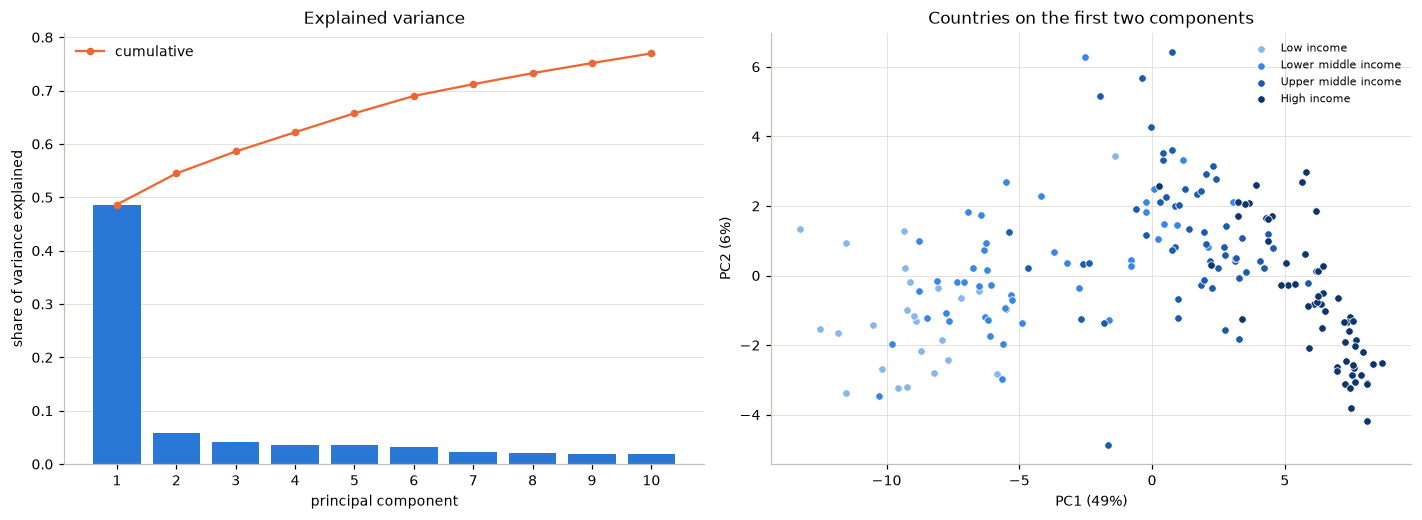

PC1 top loadings:
 hdi                         0.17
uhc index                   0.16
under5 mortality           -0.16
uhc sub capacity            0.16
health exp pc ppp           0.16
infant mortality           -0.16
gdp pc ppp                  0.16
maternal mortality ratio   -0.16

PC2 top loadings:
 raised glucose prevalence    0.43
obesity prevalence           0.35
mean bmi                     0.31
hypertension prevalence      0.26
population                  -0.24
ncd mortality 30 70          0.22
insufficient activity        0.17
pop 65plus pct              -0.17


In [16]:
# PCA of the indicators (log-transformed, standardised): how many dimensions describe the countries?
X = StandardScaler().fit_transform(clean_log[indicator_cols])
pca = PCA().fit(X)
scores = pca.transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# left: explained variance of the first 10 components
explained = pca.explained_variance_ratio_[:10]
axes[0].bar(range(1, 11), explained, color="#2a78d6")
axes[0].plot(range(1, 11), np.cumsum(explained), color="#eb6834", marker="o", markersize=4, label="cumulative")
axes[0].set_xticks(range(1, 11))
axes[0].set_xlabel("principal component")
axes[0].set_ylabel("share of variance explained")
axes[0].set_title("Explained variance")
axes[0].legend(frameon=False)
axes[0].grid(axis="x", visible=False)

# right: countries on the first two components
for g in INCOME_ORDER:
    m = (clean_log["income_group"] == g).values
    axes[1].scatter(scores[m, 0], scores[m, 1], s=24, color=INCOME_COLORS[g], label=g, edgecolor="white", linewidth=0.5)
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[1].set_title("Countries on the first two components")
axes[1].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

# indicators with the largest loadings on PC1 and PC2
loadings = pd.DataFrame(pca.components_[:2].T, index=[label(c) for c in indicator_cols], columns=["PC1", "PC2"])
print("PC1 top loadings:\n", loadings["PC1"].sort_values(key=abs, ascending=False).head(8).round(2).to_string())
print("\nPC2 top loadings:\n", loadings["PC2"].sort_values(key=abs, ascending=False).head(8).round(2).to_string())

**Result.**
- **PC1 explains 49%** of the variance of all 71 indicators; every further component explains 6% or less. Ten components together explain 77%.
- PC1 is the **development axis**: its strongest loadings are HDI, UHC index, health spending, GDP (positive) and under-5, infant and maternal mortality (negative). Low-income countries are on the left, high-income countries on the right.
- **PC2 (6%)** is a **metabolic risk** dimension: raised glucose, obesity, mean BMI, hypertension and NCD mortality. The highest PC2 scores belong to **Pacific island states** (Tonga, Kiribati, Samoa, Micronesia, Fiji) and **Middle Eastern countries** (Iraq, Libya, Syria, Egypt), which have some of the highest obesity and diabetes rates in the world. They are mostly middle-income countries, which gives the scatter plot its arch shape.

**Interpretation.** The data have one very strong dimension (development) and many small ones. This confirms Sections 4 and 6: to find specific links between health systems and diseases, the development axis has to be controlled for.

## 8 Outliers
Outliers are identified with a **robust z-score**: the distance of a value from the column median, measured in units of the median absolute deviation (MAD). Unlike the normal z-score, it is not distorted by the outliers themselves. Values with |z| > 5 are flagged, on the log-transformed data. Binary columns are excluded.

In [17]:
# Outliers: robust z-score per column on the log data (distance from the median in units of the MAD).
# |z| > 5 is flagged. Countries with many flagged values are listed.
values = clean_log.set_index("country")[indicator_cols + cause_cols]
binary = [c for c in values if set(values[c].unique()) <= {0, 1}]
values = values.drop(columns=binary)

mad = (values - values.median()).abs().median()
robust_z = (values - values.median()) / (1.4826 * mad.replace(0, np.nan))   # columns with MAD = 0 are skipped
flags = robust_z.abs() > 5

print("Countries with the most extreme values (|robust z| > 5):")
print(flags.sum(axis=1).sort_values(ascending=False).head(10).to_string())

# Example: the Central African Republic in 2019 vs. 2018 (sudden jump in the source data)
car = full[(full["country"] == "Central African Republic") & full["year"].between(2017, 2019)]
car[["year", "under5_mortality", "infant_mortality", "life_expectancy", "maternal_mortality_ratio"]]

Countries with the most extreme values (|robust z| > 5):
country
South Sudan                 24
Somalia, Fed. Rep.          23
Central African Republic    21
Chad                        21
Madagascar                  20
Niger                       19
Uganda                      19
Ethiopia                    18
Eritrea                     17
Mozambique                  17


,year,under5_mortality,infant_mortality,life_expectancy,maternal_mortality_ratio
665,2017,155.2,88.4,48.8,1093.0
666,2018,120.2,73.9,52.1,881.0
667,2019,254.7,128.9,42.2,1650.0


**Result.**
- The countries with the most extreme values are **South Sudan, Somalia, the Central African Republic, Chad, Madagascar and Niger** – the poorest, often conflict-affected countries with very high mortality from many causes at once. These are not data errors; they are the real extreme end of global health, and they should stay in the data. Spearman correlations are rank-based, so single extreme values cannot dominate the results.
- **Central African Republic (CAR)**: under-5 mortality jumps from 120 (2018) to **255** (2019) per 1,000 and life expectancy falls from 52 to **42 years**, after 155 / 49 years in 2017. Such jumps in modelled estimates are typical for countries with very little primary data, where a new survey can shift the estimates strongly. The values are reported by both the World Bank and WHO and are kept, but CAR should be mentioned as an uncertain data point.

## 9 Summary and consequences for the network

### Variables excluded from the network
The following indicators stay in the dataset but are not used as network nodes:

In [18]:
# Variables excluded from the network (they stay in the dataset)
NETWORK_EXCLUDE = {
    "population": "size, not a rate",
    "gdp_growth": "one-year economic shock (e.g. Venezuela -28%), not a structural characteristic",
    "infant_mortality": "near-duplicate of under-5 mortality (rho ~ 1)",
    "hale": "near-duplicate of life expectancy (rho ~ 1)",
    "maternal_mortality_ratio": "same quantity as the cause 'maternal conditions' (rho ~ 1)",
}
network_indicators = [c for c in indicator_cols if c not in NETWORK_EXCLUDE]
print(len(network_indicators), "indicators +", len(cause_cols), "causes =",
      len(network_indicators) + len(cause_cols), "candidate network nodes")
pd.Series(NETWORK_EXCLUDE, name="reason")

66 indicators + 139 causes = 205 candidate network nodes


population                                                   size, not a rate
gdp_growth                  one-year economic shock (e.g. Venezuela -28%),...
infant_mortality                near-duplicate of under-5 mortality (rho ~ 1)
hale                              near-duplicate of life expectancy (rho ~ 1)
maternal_mortality_ratio    same quantity as the cause 'maternal condition...
Name: reason, dtype: str

### Key findings
1. **Strong income gradient.** Health-system inputs (doctors, spending) differ by a factor of ~35 between low- and high-income countries, outcomes much less (life expectancy +18 years).
2. **Epidemiological transition.** Communicable diseases fall from 31% to 7% of deaths from low to high income, noncommunicable diseases rise from 62% to 87%. Conflict-affected countries have the lowest NCD shares.
3. **One dominant development axis.** PC1 explains 49% of the variance of all indicators, and most indicators and causes of death are correlated through wealth.
4. **A health-system signal beyond wealth exists.** After controlling for GDP, vaccine-preventable diseases, TB, maternal and neonatal conditions and malaria are lower where health-service coverage is higher.
5. **Most of the correlation between causes is wealth.** Removing GDP reduces the share of strongly correlated cause pairs from 27% to 2% and splits the large poverty cluster into specific disease groups.
6. **Treatment availability is only weakly linked to wealth**, so it can reveal specific health-system–disease links.

### Consequences for the network analysis
- **Nodes**: 139 causes of death + 66 indicators (205 candidates), without the near-duplicates and size/shock variables listed above.
- **Edges**: based on **GDP-adjusted (partial) Spearman correlations** or conditional dependencies (e.g. graphical lasso), not on raw correlations. Otherwise the network would only reproduce the development axis.
- **Robustness checks**: repeat the analysis for 2015, without the "low-mortality" causes (osteoarthritis, gout, …) and without countries with very uncertain data (e.g. CAR).

### Limitations
- Cross-sectional data (one year): all results are associations between countries, not causal effects.
- WHO cause-of-death estimates are partly model-based, especially for countries without complete death registration; some patterns (Section 6.2) may reflect the estimation method.
- About 3% of the indicator values were imputed with income-group medians (see initial EDA).